In [1]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

km_semanales = rng.integers(4, 36, size=60)

tiempo_5k = (
    40
    - 0.45 * km_semanales
    + rng.normal(0, 2.5, size=60)
)

df_5k = pd.DataFrame({
    "km_semanales": km_semanales,
    "tiempo_5k_min": np.round(tiempo_5k, 1)
})

df_5k.to_csv("5k.csv", index=False)

df_5k.head()

,km_semanales,tiempo_5k_min
0,6,42.7
1,28,26.4
2,24,27.9
3,18,29.9
4,17,33.9


In [28]:
temperatura = rng.integers(15, 34, size=90)

cafes_vendidos = (
    160
    - 3 * temperatura
    + rng.normal(0, 10, size=90)
)

df_cafe = pd.DataFrame({
    "temperatura_c": temperatura,
    "cafes_vendidos": np.maximum(
        0, np.round(cafes_vendidos)
    ).astype(int)
})

df_cafe.to_csv("cafe.csv", index=False)

df_cafe.head()

,temperatura_c,cafes_vendidos
0,29,77
1,22,95
2,15,115
3,33,54
4,18,109


In [3]:
df_5k.describe()

,km_semanales,tiempo_5k_min
count,60.000000,60.000000
mean,20.300000,30.883333
std,8.836174,4.365705
min,5.000000,24.400000
25%,14.250000,27.575000
50%,20.500000,30.050000
75%,28.000000,33.825000
max,35.000000,42.700000


In [4]:
import matplotlib.pyplot as plt

In [5]:
datos = df_5k

In [6]:
datos.head()

,km_semanales,tiempo_5k_min
0,6,42.7
1,28,26.4
2,24,27.9
3,18,29.9
4,17,33.9


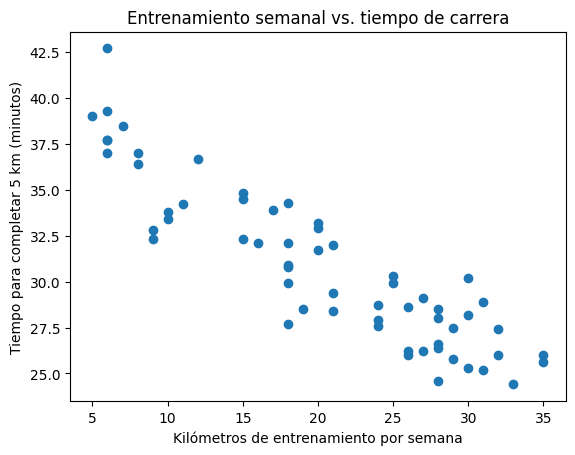

In [7]:
plt.scatter(datos["km_semanales"], datos["tiempo_5k_min"])

plt.xlabel("Kilómetros de entrenamiento por semana")
plt.ylabel("Tiempo para completar 5 km (minutos)")
plt.title("Entrenamiento semanal vs. tiempo de carrera")

plt.show()


In [8]:
X = datos[["km_semanales"]]
y = datos["tiempo_5k_min"]


In [9]:
from sklearn.linear_model import LinearRegression

modelo = LinearRegression()

modelo.fit(X, y)


LinearRegression()

In [10]:
print("Pendiente:", modelo.coef_[0])
print("Intercepto:", modelo.intercept_)

Pendiente: -0.4461424912082665
Intercepto: 39.940025904861145


In [11]:
predicciones = modelo.predict(X)

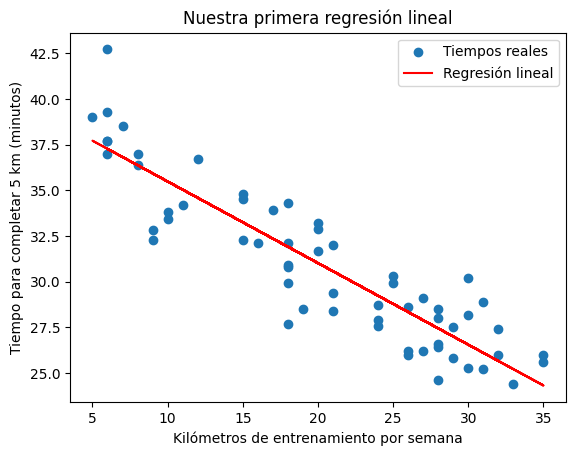

In [12]:
plt.scatter(X["km_semanales"], y, label="Tiempos reales")

plt.plot(
    X["km_semanales"],
    predicciones,
    color="red",
    label="Regresión lineal"
)

plt.xlabel("Kilómetros de entrenamiento por semana")
plt.ylabel("Tiempo para completar 5 km (minutos)")
plt.title("Nuestra primera regresión lineal")

plt.legend()
plt.show()


In [13]:
nuevo_corredor = pd.DataFrame({
    "km_semanales": [18]
})

tiempo_estimado = modelo.predict(nuevo_corredor)

print("Tiempo estimado:", round(tiempo_estimado[0], 1), "minutos")


Tiempo estimado: 31.9 minutos


In [14]:
pendiente = modelo.coef_[0]
intercepto = modelo.intercept_

resultado_manual = intercepto + pendiente * 18

print("Predicción con la fórmula:", round(resultado_manual, 1))
print("Predicción con Python:", round(tiempo_estimado[0], 1))


Predicción con la fórmula: 31.9
Predicción con Python: 31.9


In [15]:
nuevos_corredores = pd.DataFrame({
    "km_semanales": [8, 18, 30]
})

nuevos_corredores["tiempo_estimado"] = modelo.predict(
    nuevos_corredores[["km_semanales"]]
)

nuevos_corredores


,km_semanales,tiempo_estimado
0,8,36.370886
1,18,31.909461
2,30,26.555751


In [16]:
from sklearn.metrics import mean_absolute_error

error_promedio = mean_absolute_error(y, predicciones)

print("Error promedio:", round(error_promedio, 2), "minutos")


Error promedio: 1.55 minutos


In [17]:
datos = df_cafe

In [18]:
datos.head()

,temperatura_c,cafes_vendidos
0,24,78
1,23,94
2,18,114
3,22,114
4,19,132


In [19]:
datos.describe()

,temperatura_c,cafes_vendidos
count,90.000000,90.000000
mean,23.500000,89.522222
std,5.202096,20.182442
min,15.000000,47.000000
25%,19.250000,73.500000
50%,23.000000,90.000000
75%,27.750000,104.000000
max,33.000000,132.000000


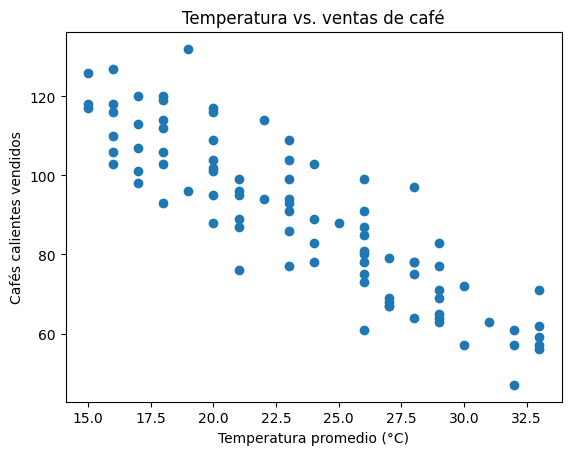

In [20]:
plt.scatter(
    datos["temperatura_c"],
    datos["cafes_vendidos"]
)

plt.xlabel("Temperatura promedio (°C)")
plt.ylabel("Cafés calientes vendidos")
plt.title("Temperatura vs. ventas de café")

plt.show()


In [21]:
from sklearn.linear_model import LinearRegression

X = datos[["temperatura_c"]]
y = datos["cafes_vendidos"]

modelo = LinearRegression()
modelo.fit(X, y)


LinearRegression()

In [22]:
print("Pendiente:", modelo.coef_[0])
print("Intercepto:", modelo.intercept_)


Pendiente: -3.41810255345651
Intercepto: 169.8476322284502


In [23]:
manana = pd.DataFrame({
    "temperatura_c": [20]
})

prediccion = modelo.predict(manana)

print("Ventas estimadas:", round(prediccion[0]), "cafés")


Ventas estimadas: 101 cafés


In [24]:
pronostico = pd.DataFrame({
    "temperatura_c": [16, 24, 32]
})

pronostico["ventas_estimadas"] = modelo.predict(
    pronostico[["temperatura_c"]]
).round().astype(int)

pronostico


,temperatura_c,ventas_estimadas
0,16,115
1,24,88
2,32,60


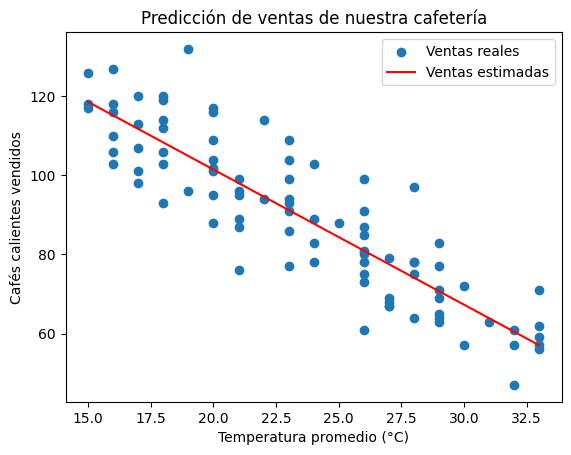

In [25]:
import numpy as np

temperaturas = np.linspace(
    datos["temperatura_c"].min(),
    datos["temperatura_c"].max(),
    100
)

nuevas_temperaturas = pd.DataFrame({
    "temperatura_c": temperaturas
})

ventas_estimadas = modelo.predict(nuevas_temperaturas)

plt.scatter(
    datos["temperatura_c"],
    datos["cafes_vendidos"],
    label="Ventas reales"
)

plt.plot(
    temperaturas,
    ventas_estimadas,
    color="red",
    label="Ventas estimadas"
)

plt.xlabel("Temperatura promedio (°C)")
plt.ylabel("Cafés calientes vendidos")
plt.title("Predicción de ventas de nuestra cafetería")

plt.legend()
plt.show()

In [26]:
cafes_estimados = 85
leche_por_cafe = 200

litros_leche = (
    cafes_estimados * leche_por_cafe
) / 1000

print("Leche necesaria:", litros_leche, "litros")


Leche necesaria: 17.0 litros


In [27]:
from sklearn.metrics import mean_absolute_error

predicciones = modelo.predict(X)

error = mean_absolute_error(y, predicciones)

print("Error promedio:", round(error, 2), "cafés")


Error promedio: 7.35 cafés
